<h1 style="color:red; text-align:center">Revision 1</h1>

<span style="color:#c00">Instructor: Dr. Khaled Mohamad</span>

---
> **Instructions:** Answer all questions in order, write clean and well-commented code, and **use consistent Markdown formatting for both questions and answers. It is weighted at 20%.**

---

### Dataset Overview
You will work with the **Titanic** dataset (built into Seaborn) and the **Tips** dataset (also built into Seaborn). No file uploads are needed.

---

In [25]:
#imports the necessary lib
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")

---
<h1 style="color:blue; text-align:center">Part 1: Load and Explore the Titanic Dataset</h1>

---

### Q1. Load & Inspect

1. Load the Titanic dataset using `sns.load_dataset('titanic')` and store it in a variable called `df`.
2. Print the **shape** of the dataset.
3. Display the **first 6 rows**.
4. Print the **column names**.

### ANSWER

In [29]:
# 1)
df = sns.load_dataset('titanic')

# 2)
print("Shape:", df.shape)

# 3)
display(df.head(6))

# 4)
print("Columns:", df.columns.tolist())

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True


Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


---
### Q2. Data Types & Missing Values

1. Use `.info()` to print column data types and non-null counts.
2. Print the **number of missing values per column** using `.isnull().sum()`.
3. Which column has the **most missing values**? Write your answer in a Markdown cell.

### ANSWER

In [32]:
# 1)
df.info()

# 2)
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
survived         0
pclass           0
sex              0
age            177
sib

**Q2.3.Your answer :**

> deck

---
### Q3. Basic Statistics

1. Use `.describe()` to display summary statistics for numeric columns.
2. From the output, answer in a Markdown cell:
   - What is the **mean age** of passengers?
   - What is the **maximum fare** paid?
   - What percentage of passengers survived? *(Hint: look at the `survived` mean, it represents the survival rate)*

### ANSWER

In [36]:
# 1)
print(df.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


**Answer Q3.2:**

- 29.7
- 512.33
- 38.4%

---
### Q4. Duplicates & Categorical Summary

1. Check how many **duplicate rows** exist in the dataset.
2. Use `.describe(include=['object', 'category'])` to get a summary of categorical columns.
3. From the output, answer in a Markdown cell:
   - What is the most common **sex** in the dataset and how many rows does it appear in?
   - What is the most common **embarkation port**?

### ANSWER

In [40]:
# 1)
print("Duplicates:", df.duplicated().sum())

# 2)
display(df.describe(include=['object', 'category']))

Duplicates: 107


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


**Answer Q4.3:**

- male
- Southampton

---
<h1 style="color:blue; text-align:center">Part 2: Data Cleaning</h1>

---

### Q5. Handle Missing Values

Create a new DataFrame called `df_clean` and apply the following cleaning steps **in order**:

1. **Drop** the `deck` column (too many missing values).
2. **Fill** missing values in the `age` column with the **median** age.
3. **Fill** missing values in the `embarked` column with the **mode** (most frequent value).
4. **Fill** missing values in the `embark_town` column with its **mode**.
5. After cleaning, print `.isnull().sum()` to confirm no missing values remain.

### ANSWER

In [45]:
# Make a copy
df_clean = df.copy()

# Step 1: Drop deck
df_clean.drop(columns=['deck'], inplace=True)

# Step 2: Fill age with median
df_clean['age'].fillna(df_clean['age'].median(), inplace=True)

# Step 3: Fill embarked with mode
df_clean['embarked'].fillna(df_clean['embarked'].mode()[0], inplace=True)

# Step 4: Fill embark town with mode
df_clean['embark_town'].fillna(df_clean['embark_town'].mode()[0], inplace=True)

# Step 5: Confirm no missing values remain
print(df_clean.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


---
### Q6. Remove Duplicates & Redundant Columns

Continue working with `df_clean`:

1. Remove **duplicate rows** from `df_clean` using `drop_duplicates(inplace=True)`.
2. Drop the columns `'alive'` and `'embark_town'` - **REASON** - they are redundant (duplicated information from `survived` and `embarked`).
3. Print the **shape before and after** to show how many rows were removed.
4. Display the first 5 rows of the cleaned DataFrame.

### ANSWER

In [51]:
# 3) Print shape before
print("Shape before:", df_clean.shape)

# 1) Remove duplicate rows
df_clean.drop_duplicates(inplace=True)

# 2) Drop redundant columns
df_clean.drop(columns=['alive', 'embark_town'], inplace=True)

# 3) Print shape after
print("Shape after:", df_clean.shape)

# 4) Display the first 5 rows
display(df_clean.head())

Shape before: (891, 14)
Shape after: (775, 12)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,True


---
### Q7. Outlier Detection

1. Create a **boxplot** for the `fare` column to visually identify outliers.
2. Use the **IQR method** to calculate the upper bound for outliers:
   - `Q1 = fare.quantile(0.25)`, `Q3 = fare.quantile(0.75)`
   - `IQR = Q3 - Q1`
   - `upper_bound = Q3 + 1.5 * IQR`
3. Print how many rows have a fare above the upper bound.
4. Create a new column `fare_capped` that **clips** the fare at the upper bound using `.clip(upper=upper_bound)`.

### ANSWER

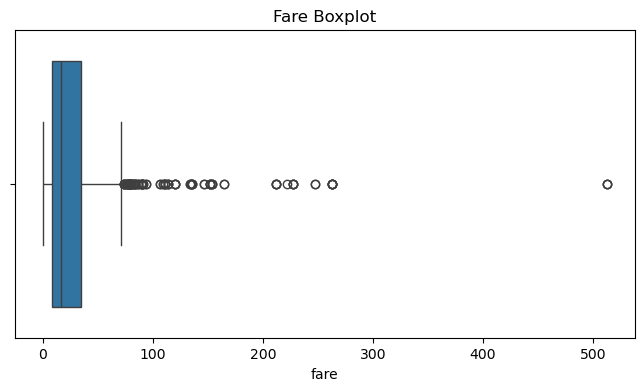

In [53]:
# Part 1: boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['fare'])
plt.title('Fare Boxplot')
plt.show()

In [55]:
# Part 2: IQR method
Q1 = df_clean['fare'].quantile(0.25)
Q3 = df_clean['fare'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

In [57]:
# Part 3: count outliers
outliers_count = (df_clean['fare'] > upper_bound).sum()
print(f"Number of rows with fare above upper bound ({upper_bound}): {outliers_count}")

Number of rows with fare above upper bound (73.41975000000001): 102


In [59]:
# Part 4: cap fares
df_clean['fare_capped'] = df_clean['fare'].clip(upper=upper_bound)

---
<h1 style="color:blue; text-align:center">Part 3: Filtering, Sorting & Grouping</h1>

---

### Q8. Filtering

Using `df_clean`:

1. Filter passengers who **survived** (`survived == 1`) AND were in **First class** (`class == 'First'`). How many are there?
2. Filter passengers who were **older than 60**. Print how many there are and display their names if the column exists, otherwise display the filtered DataFrame.
3. Filter passengers who paid a fare **above $50** and were **female**. How many rows match?

### ANSWER

In [61]:
# Part 1
survived_first = df_clean[(df_clean['survived'] == 1) & (df_clean['class'] == 'First')]
print("1. Survived & First class count:", len(survived_first))

1. Survived & First class count: 133


In [63]:
# Part 2
older_than_60 = df_clean[df_clean['age'] > 60]
print("2. Older than 60 count:", len(older_than_60))
display(older_than_60)

2. Older than 60 count: 21


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone,fare_capped
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,True,10.50000
54,0,1,male,65.0,0,1,61.9792,C,First,man,True,False,61.97920
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,True,34.65420
116,0,3,male,70.5,0,0,7.7500,Q,Third,man,True,True,7.75000
170,0,1,male,61.0,0,0,33.5000,S,First,man,True,True,33.50000
252,0,1,male,62.0,0,0,26.5500,S,First,man,True,True,26.55000
275,1,1,female,63.0,1,0,77.9583,S,First,woman,False,False,73.41975
280,0,3,male,65.0,0,0,7.7500,Q,Third,man,True,True,7.75000
326,0,3,male,61.0,0,0,6.2375,S,Third,man,True,True,6.23750
438,0,1,male,64.0,1,4,263.0000,S,First,man,True,False,73.41975


In [65]:
# Part 3
fare_50_female = df_clean[(df_clean['fare'] > 50) & (df_clean['sex'] == 'female')]
print("3. Fare > 50 and female count:", len(fare_50_female))

3. Fare > 50 and female count: 84


---
### Q9. Sorting

Using `df_clean`:

1. Sort the DataFrame by `fare` in **descending order** and display the **top 5 rows** (only columns: `sex`, `age`, `class`, `fare`, `survived`).
2. Sort by `age` in **ascending order** and display the **5 youngest passengers**.
3. In a Markdown cell, state one observation from each sorted result.

### ANSWER

In [69]:
#1)
print("Top 5 highest fares:")
display(df_clean.sort_values(by='fare', ascending=False)[['sex', 'age', 'class', 'fare', 'survived']].head(5))

#2)
print("5 youngest passengers:")
display(df_clean.sort_values(by='age', ascending=True)[['sex', 'age', 'class', 'fare', 'survived']].head(5))

Top 5 highest fares:


,sex,age,class,fare,survived
258,female,35.0,First,512.3292,1
737,male,35.0,First,512.3292,1
679,male,36.0,First,512.3292,1
88,female,23.0,First,263.0000,1
341,female,24.0,First,263.0000,1


5 youngest passengers:


,sex,age,class,fare,survived
803,male,0.42,Third,8.5167,1
755,male,0.67,Second,14.5000,1
469,female,0.75,Third,19.2583,1
831,male,0.83,Second,18.7500,1
78,male,0.83,Second,29.0000,1


**Your observations:**

- The passengers with the highest ticket prices travelled predominantly in first class, and most of them survived.
- Among the youngest passengers there were many children (age close to 0), and many of them also survived (probably due to the “children and women first” rule).

---
### Q10. GroupBy & Aggregation

Using `df_clean`:

1. Use `.groupby('sex')['survived'].mean()` to find the **survival rate by sex**. Round to 2 decimal places.
2. Use `.groupby('class')['survived'].mean()` to find the **survival rate by passenger class**.
3. Use `.groupby('class')['fare'].mean()` to find the **average fare per class**.
4. In a Markdown cell, write **two observations** from the results above.

### ANSWER

In [74]:
#1)
print("Survival rate by sex:")
print(df_clean.groupby('sex')['survived'].mean().round(2))

#2)
print("\nSurvival rate by class:")
print(df_clean.groupby('class')['survived'].mean().round(2))

#3)
print("\nAverage fare per class:")
print(df_clean.groupby('class')['fare'].mean().round(2))

Survival rate by sex:
sex
female    0.74
male      0.22
Name: survived, dtype: float64

Survival rate by class:
class
First     0.63
Second    0.51
Third     0.26
Name: survived, dtype: float64

Average fare per class:
class
First     85.68
Second    21.89
Third     13.59
Name: fare, dtype: float64


**Your observations:**

1. Women have a significantly higher survival rate than men.
2. First class passengers had a much higher survival rate and paid, on average, much more for their tickets than second and third class passengers.

---
<h1 style="color:blue; text-align:center">Part 4: Visualization</h1>

---

### Q11. Histogram & Count Plot

Create a figure with **two subplots side by side** (`figsize=(12, 4)`):

- **Left subplot:** Histogram of `age` using `sns.histplot` with `kde=True` and `bins=20`. Title: `'Age Distribution'`.
- **Right subplot:** Count plot of `survived` using `sns.countplot`. Title: `'Survival Count'`.

Use `plt.tight_layout()` and `plt.show()`.

### ANSWER

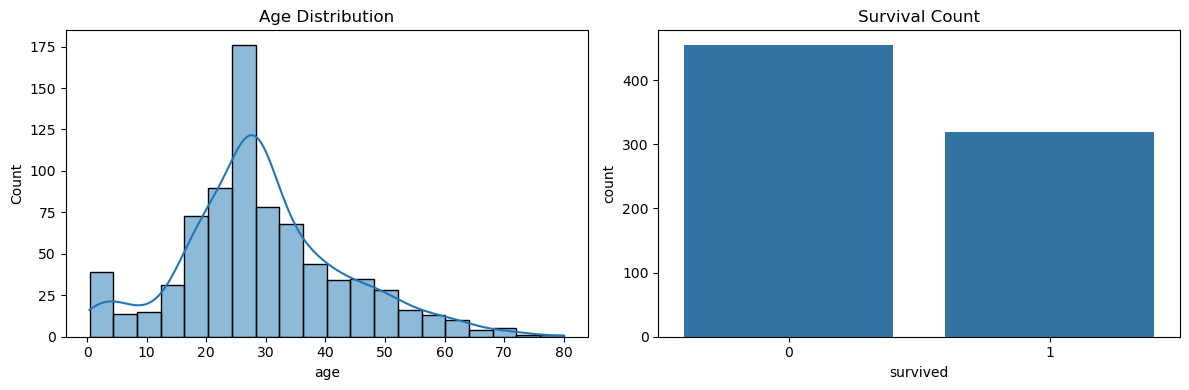

In [77]:
plt.figure(figsize=(12, 4))

# Left: Age distribution
plt.subplot(1, 2, 1)
sns.histplot(df_clean['age'], kde=True, bins=20)
plt.title('Age Distribution')

# Right: Survival count
plt.subplot(1, 2, 2)
sns.countplot(x='survived', data=df_clean)
plt.title('Survival Count')

plt.tight_layout()
plt.show()

---
### Q12. Categorical Plots

Create a figure with **two subplots side by side** (`figsize=(12, 5)`):

- **Left:** `sns.countplot` with `x='sex'` and `hue='survived'`. Title: `'Survival by Sex'`.
- **Right:** `sns.countplot` with `x='class'` and `hue='survived'`. Title: `'Survival by Class'`.

In a Markdown cell below, interpret each plot in **one sentence each**.

### ANSWER

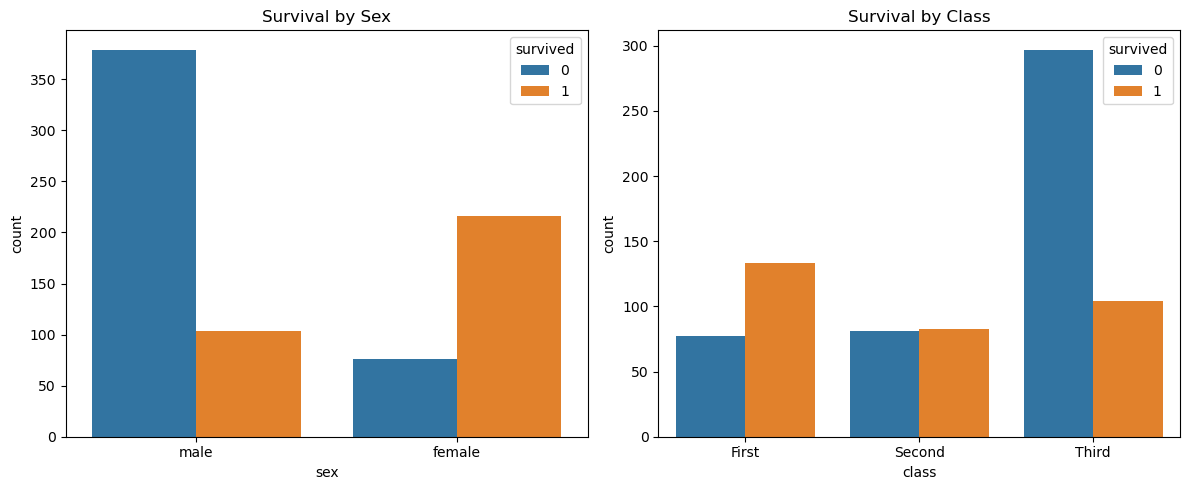

In [79]:
plt.figure(figsize=(12, 5))

# Left: Survival by Sex
plt.subplot(1, 2, 1)
sns.countplot(x='sex', hue='survived', data=df_clean)
plt.title('Survival by Sex')

# Right: Survival by Class
plt.subplot(1, 2, 2)
sns.countplot(x='class', hue='survived', data=df_clean)
plt.title('Survival by Class')

plt.tight_layout()
plt.show()

**Your interpretations:**

- The graph shows that women predominate among the survivors, while the overwhelming majority of the dead are men.
- Third-class passengers suffered the greatest losses in absolute terms, while in first class there were more survivors than fatalities.

---
### Q13. Boxplot & Scatter Plot

1. Create a **boxplot** using `sns.boxplot(x='class', y='age', hue='survived', data=df_clean)`. Title: `'Age by Class and Survival'`.
2. Create a **scatter plot** using `sns.scatterplot(x='age', y='fare_capped', hue='survived', data=df_clean, alpha=0.6)`. Title: `'Age vs Fare (Capped) by Survival'`.
3. In a Markdown cell, write **one observation** from each plot.

### ANSWER

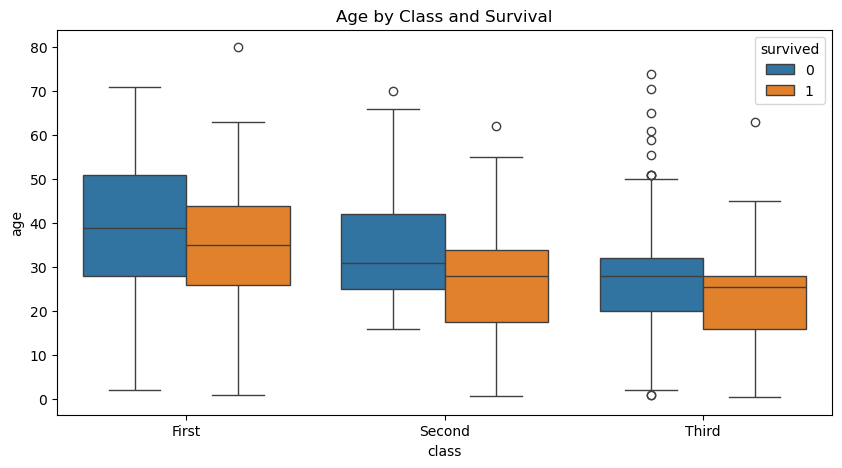

In [82]:
# Part 1. Boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(x='class', y='age', hue='survived', data=df_clean)
plt.title('Age by Class and Survival')
plt.show()

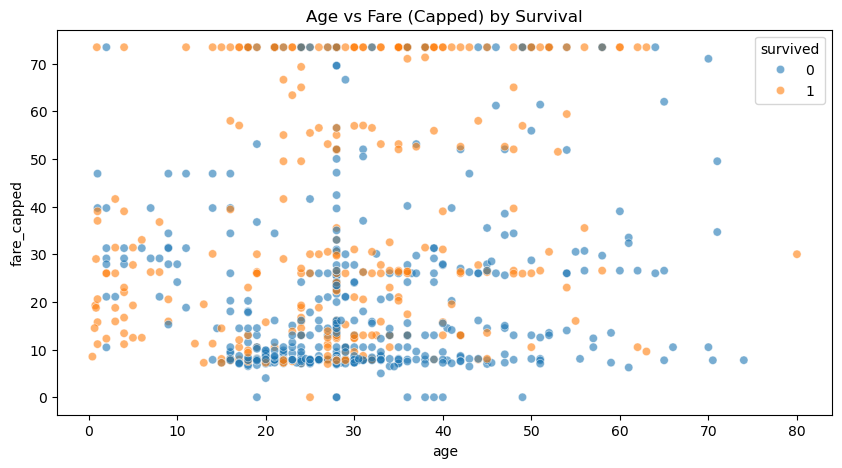

In [84]:
# Part 2. Scatter plot
plt.figure(figsize=(10, 5))
sns.scatterplot(x='age', y='fare_capped', hue='survived', data=df_clean, alpha=0.6)
plt.title('Age vs Fare (Capped) by Survival')
plt.show()

**Your observations:**

- The median age of first class passengers is higher than that of second and third class passengers.
- Passengers who pay a higher ticket price tend to survive more often, regardless of age.

---
### Q14. Correlation Heatmap

1. Select all **numeric columns** from `df_clean` using `select_dtypes(include=np.number)`.
2. Compute the **correlation matrix** using `.corr()`.
3. Plot it as a **heatmap** using `sns.heatmap(... annot=True, cmap='coolwarm', center=0)`. Set `figsize=(8, 6)`. Title: `'Correlation Heatmap'`.
4. In a Markdown cell, identify the **two features most positively correlated with survival**.

### ANSWER

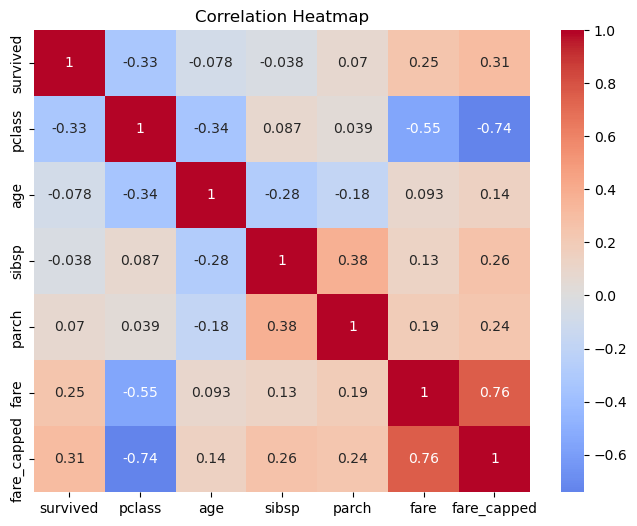

In [88]:
# 1) Select numeric columns
numeric_df = df_clean.select_dtypes(include=np.number)

# 2) Compute correlation matrix
corr_matrix = numeric_df.corr()

# 3) Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

**Answer Q14.4:** 
fare and fare_capped

---
<h1 style="color:blue; text-align:center">Part 5: Tips Dataset: Filtering & Grouping</h1>

---

### Q15. Load and Filter the Tips Dataset

1. Load the **tips** dataset: `tips = sns.load_dataset('tips')`.
2. Display the first 5 rows and print the shape.
3. Filter only **dinner** orders where the **total bill is above $20**. How many rows match?
4. From those filtered rows, find the **average tip**.

### ANSWER

In [91]:
# 1)
tips = sns.load_dataset('tips')

# 2)
display(tips.head())
print("Tips shape:", tips.shape)

# 3)
dinner_above_20 = tips[(tips['time'] == 'Dinner') & (tips['total_bill'] > 20)]
print("Matching rows count:", len(dinner_above_20))

# 4)
avg_tip = dinner_above_20['tip'].mean()
print("Average tip:", avg_tip)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Tips shape: (244, 7)
Matching rows count: 81
Average tip: 3.8858024691358026


---
### Q16. Grouping the Tips Dataset

Using the full `tips` DataFrame:

1. Use `.groupby('day')['tip'].mean()` to find the **average tip by day**. Sort from highest to lowest.
2. Use `.groupby('smoker')['tip'].mean()` to compare tips between **smokers and non-smokers**.
3. In a Markdown cell, answer: **Do smokers tip more or less on average?**

### ANSWER

In [93]:
#1)
avg_tip_day = tips.groupby('day')['tip'].mean().sort_values(ascending=False)
print("Average tip by day:\n", avg_tip_day)

#2)
avg_tip_smoker = tips.groupby('smoker')['tip'].mean()
print("\nAverage tip by smoker status:\n", avg_tip_smoker)

Average tip by day:
 day
Sun     3.255132
Sat     2.993103
Thur    2.771452
Fri     2.734737
Name: tip, dtype: float64

Average tip by smoker status:
 smoker
Yes    3.008710
No     2.991854
Name: tip, dtype: float64


**Answer Q16.3:** 
Smokers and non-smokers leave about the same tips on average.

---
### Q17. Visualize the Tips Dataset

Create a figure with **three subplots** (`figsize=(15, 4)`):

- **Left:** Scatter plot of `total_bill` vs `tip` (use `plt.scatter`). Title: `'Tip vs Total Bill'`.
- **Center:** Bar plot of average tip by day (use `.plot(kind='bar')` on the grouped result). Title: `'Average Tip by Day'`.
- **Right:** Histogram of `tip` with `bins=15` and `edgecolor='k'`. Title: `'Tip Distribution'`.

Add axis labels and `plt.tight_layout()`.

### ANSWER

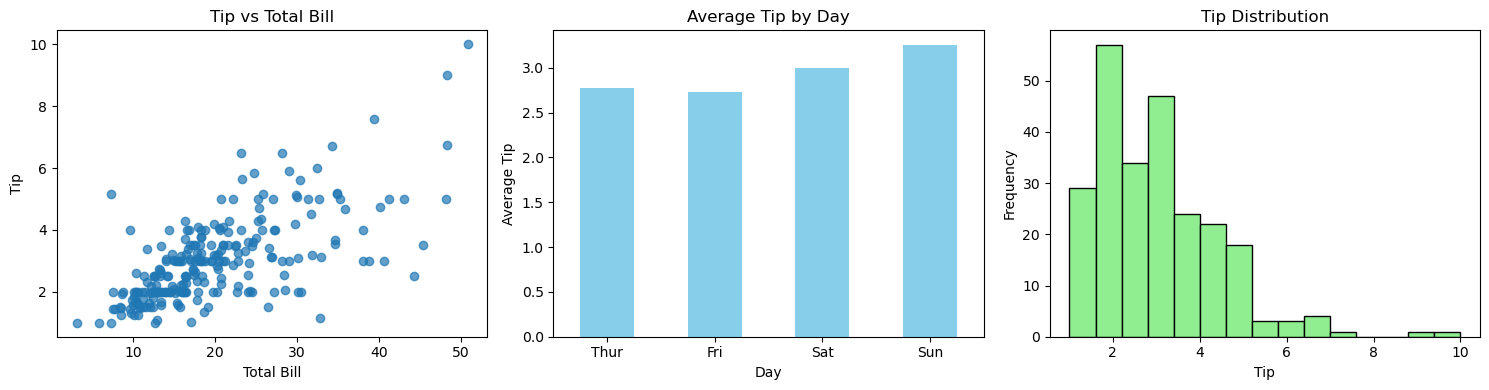

In [96]:
plt.figure(figsize=(15, 4))

# Left: Scatter plot of total_bill vs tip
plt.subplot(1, 3, 1)
plt.scatter(tips['total_bill'], tips['tip'], alpha=0.7)
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.title('Tip vs Total Bill')

# Center: Bar plot of average tip by day
plt.subplot(1, 3, 2)
tips.groupby('day')['tip'].mean().plot(kind='bar', color='skyblue')
plt.xlabel('Day')
plt.ylabel('Average Tip')
plt.title('Average Tip by Day')
plt.xticks(rotation=0)

# Right: Histogram of tip
plt.subplot(1, 3, 3)
plt.hist(tips['tip'], bins=15, edgecolor='k', color='lightgreen')
plt.xlabel('Tip')
plt.ylabel('Frequency')
plt.title('Tip Distribution')

plt.tight_layout()
plt.show()

---
## Linear Regression on Tips

Using the `tips` dataset:

1. Extract `X` = `total_bill` (reshape to column: `tips[['total_bill']].values`) and `y` = `tip` (`tips[['tip']].values`).
2. Train a `LinearRegression` model from `sklearn.linear_model`.
3. Print the **coefficient** and **intercept**. Interpret them in a sentence: "For every extra 1 dollar on the bill, the tip increases by..."
4. Plot the data as a scatter plot and overlay the **regression line** in red.
5. Predict the tip for a total bill of **$30**.

### ANSWER

Coefficient (Slope): 0.1050
Intercept: 0.9203
Interpretation: "For every extra 1 dollar on the bill, the tip increases by $0.11."


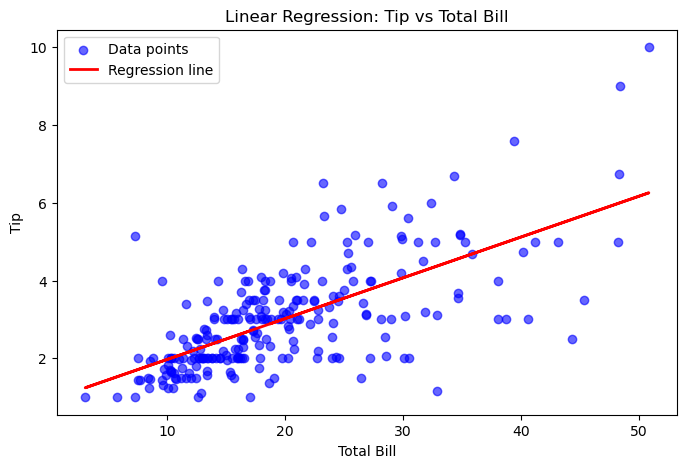

Predicted tip for a $30 bill: $4.07


In [104]:
from sklearn.linear_model import LinearRegression

# 1. Extract X and y
X = tips[['total_bill']].values
y = tips[['tip']].values

# 2. Train model
model = LinearRegression()
model.fit(X, y)

# 3. Print coefficient and intercept
coef = model.coef_[0][0]
intercept = model.intercept_[0]
print(f"Coefficient (Slope): {coef:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f'Interpretation: "For every extra 1 dollar on the bill, the tip increases by ${coef:.2f}."')

# 4. Scatter plot + regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, label='Data points')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression line')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.title('Linear Regression: Tip vs Total Bill')
plt.legend()
plt.show()

# 5. Predict tip for $30 total bill
pred_30 = model.predict([[30]])[0][0]
print(f"Predicted tip for a $30 bill: ${pred_30:.2f}")